In [1]:
# Importar las librerias
import os
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    GroupShuffleSplit, GroupKFold, GridSearchCV, RandomizedSearchCV,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)
from sklearn.inspection import permutation_importance

os.makedirs("output", exist_ok=True)

In [3]:
# Leer los datos de nuestro dataset
datos = pd.read_csv('https://github.com/rodrigo-elias-01/Data-Science-Grupo15/raw/refs/heads/main/data/EPHC_2025_limpio.csv')
datos.head()

,UPM,NVIVI,NHOGA,L02,DPTO,NOMBRE_DPTO,P02,grupo_etario,añoest,ED0504,nivel_educ_simplificado,ED06C,ED08,asiste_actualmente,ED09,ED10
0,14,13,1,1,0,Asunción,65,65+,15,2403,Terciaria/Universitaria,14.0,NaN,NaN,NaN,NaN
1,14,13,1,2,0,Asunción,69,65+,18,2406,Terciaria/Universitaria,10.0,NaN,NaN,NaN,NaN
2,14,15,1,1,0,Asunción,78,65+,6,306,Primaria (EEB 1-6),NaN,NaN,NaN,NaN,NaN
3,14,15,1,2,0,Asunción,78,65+,12,606,Secundaria/Media,NaN,NaN,NaN,NaN,NaN
4,14,16,1,1,0,Asunción,40,35-49,17,2405,Terciaria/Universitaria,1.0,19.0,0.0,NaN,2.0


###1. Carga y definición de la tarea

In [4]:
df = datos.copy()



# Población objetivo: edad escolar 6-17
df = df[df["P02"].between(6, 17)].copy()

# objetivo: 1 = no asiste / abandonó; 0 = asiste
df = df.dropna(subset=["asiste_actualmente"]).copy()
df["target_no_asiste"] = (df["asiste_actualmente"].astype(int) == 0).astype(int)

print("Registros 6-17 con target válido:", len(df))
print(df["target_no_asiste"].value_counts(normalize=True).rename("proporción"))


Registros 6-17 con target válido: 11796
target_no_asiste
0    0.96414
1    0.03586
Name: proporción, dtype: float64


###2. Variables predictoras y grupos

In [5]:
num_cols = ["P02", "añoest"]
cat_cols = ["NOMBRE_DPTO", "nivel_educ_simplificado"]

X = df[num_cols + cat_cols].copy()
y = df["target_no_asiste"].copy()
groups = df["UPM"].copy()

X["P02"] = pd.to_numeric(X["P02"], errors="coerce")
X["añoest"] = pd.to_numeric(X["añoest"], errors="coerce")


###3. Preprocesamiento

In [6]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Se agrega sparse_output=False para evitar matrices dispersas incompatibles con HistGradientBoosting
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])


###4. Partición train/test agrupada por UPM

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()

print("Train:", X_train.shape, "Test:", X_test.shape)
print("UPM train/test:", groups_train.nunique(), groups.iloc[test_idx].nunique())

cv = GroupKFold(n_splits=5)


Train: (9411, 4) Test: (2385, 4)
UPM train/test: 1372 344


###5. Modelos y búsqueda de hiperparámetros

In [8]:
pipe_logit = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

pipe_rf = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

pipe_hgb = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", HistGradientBoostingClassifier(random_state=42))
])

param_logit = {
    "clf__C": [0.01, 0.1, 1.0, 10.0],
    "clf__penalty": ["l2"]
}

param_rf = {
    "clf__n_estimators": [300, 600],
    "clf__max_depth": [None, 10, 20],
    "clf__min_samples_leaf": [1, 5, 10]
}

param_hgb = {
    "clf__learning_rate": [0.05, 0.10],
    "clf__max_iter": [200, 400],
    "clf__max_leaf_nodes": [15, 31],
    "clf__l2_regularization": [0.0, 1.0]
}

search_logit = GridSearchCV(
    pipe_logit,
    param_logit,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

search_rf = RandomizedSearchCV(
    pipe_rf,
    param_rf,
    n_iter=12,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True,
    random_state=42,
    return_train_score=True
)

search_hgb = RandomizedSearchCV(
    pipe_hgb,
    param_hgb,
    n_iter=12,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True,
    random_state=42,
    return_train_score=True
)

search_logit.fit(X_train, y_train, groups=groups_train)
search_rf.fit(X_train, y_train, groups=groups_train)
search_hgb.fit(X_train, y_train, groups=groups_train)

busquedas = {
    "Regresión logística": search_logit,
    "Random Forest": search_rf,
    "HistGradientBoosting": search_hgb
}

for nombre, busqueda in busquedas.items():
    print(f"\n{nombre}")
    print("Mejores hiperparámetros:", busqueda.best_params_)
    print("Mejor F1 CV:", round(busqueda.best_score_, 4))

# Modelo ganador por F1 de validación cruzada
best_name = max(busquedas, key=lambda k: busquedas[k].best_score_)
best_model = busquedas[best_name].best_estimator_
print("\nModelo seleccionado:", best_name)

# Baseline
baseline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(X_train, y_train)



Regresión logística
Mejores hiperparámetros: {'clf__C': 0.1, 'clf__penalty': 'l2'}
Mejor F1 CV: 0.2615

Random Forest
Mejores hiperparámetros: {'clf__n_estimators': 600, 'clf__min_samples_leaf': 5, 'clf__max_depth': None}
Mejor F1 CV: 0.4112

HistGradientBoosting
Mejores hiperparámetros: {'clf__max_leaf_nodes': 15, 'clf__max_iter': 200, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 1.0}
Mejor F1 CV: 0.5399

Modelo seleccionado: HistGradientBoosting


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['P02', 'añoest']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['NOMBRE_DPTO',
                                                   'nivel_educ_simplificado'])])),
                ('clf', DummyClassifier(strategy='most_frequent'))])

###6. Métricas de validación cruzada

In [9]:
def resumen_cv(modelo, nombre):
    scores = cross_validate(
        modelo, X_train, y_train, groups=groups_train, cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1,
        return_train_score=True
    )
    fila = {"modelo": nombre}
    for metrica in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        fila[f"{metrica}_cv_mean"] = scores[f"test_{metrica}"].mean()
        fila[f"{metrica}_cv_std"] = scores[f"test_{metrica}"].std()
        fila[f"{metrica}_train_mean"] = scores[f"train_{metrica}"].mean()
    return fila

cv_resumen = pd.DataFrame([
    resumen_cv(baseline, "Línea base (clase mayoritaria)"),
    resumen_cv(search_logit.best_estimator_, "Regresión logística"),
    resumen_cv(search_rf.best_estimator_, "Random Forest"),
    resumen_cv(search_hgb.best_estimator_, "HistGradientBoosting"),
])

cv_resumen.to_csv("output/metricas_cv.csv", index=False)
print("\nMétricas CV:")
cv_resumen


Métricas CV:


,modelo,accuracy_cv_mean,accuracy_cv_std,accuracy_train_mean,precision_cv_mean,precision_cv_std,precision_train_mean,recall_cv_mean,recall_cv_std,recall_train_mean,f1_cv_mean,f1_cv_std,f1_train_mean,roc_auc_cv_mean,roc_auc_cv_std,roc_auc_train_mean
0,Línea base (clase mayoritaria),0.964084,0.003270,0.964085,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,0.500000
1,Regresión logística,0.830201,0.015705,0.832855,0.155434,0.015569,0.161583,0.835369,0.036585,0.871917,0.261471,0.020630,0.272607,0.923131,0.008210,0.933447
2,Random Forest,0.917969,0.007819,0.927266,0.278427,0.038238,0.321687,0.795832,0.036166,0.922387,0.411206,0.043611,0.476893,0.938538,0.009916,0.978492
3,HistGradientBoosting,0.971735,0.001970,0.977181,0.651991,0.053146,0.745833,0.463450,0.030041,0.553272,0.539853,0.019507,0.635206,0.940393,0.017283,0.973813


###7. Evaluación final sobre test: una sola vez





Métricas test:


,modelo,accuracy,precision,recall,f1,roc_auc
0,Línea base (clase mayoritaria),0.9644,0.0000,0.0,0.0000,0.5000
1,HistGradientBoosting,0.9711,0.6538,0.4,0.4964,0.9222



Brecha train-test:


,modelo,accuracy_train,accuracy_test,f1_train,f1_test,roc_auc_train,roc_auc_test,brecha_f1,brecha_auc
0,HistGradientBoosting,0.9765,0.9711,0.6248,0.4964,0.9718,0.9222,0.1284,0.0496


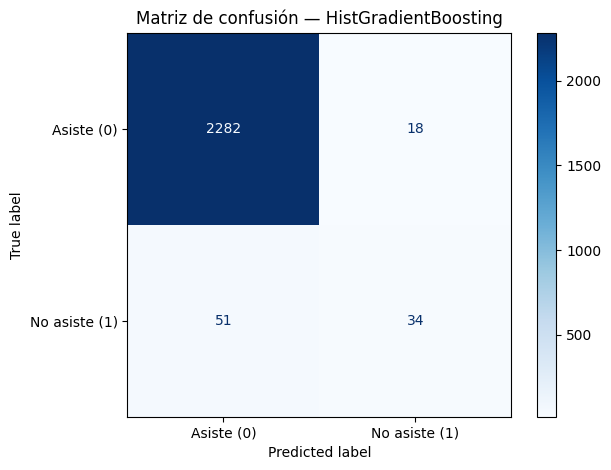


Reporte de clasificación:


'               precision    recall  f1-score   support\n\n   Asiste (0)       0.98      0.99      0.99      2300\nNo asiste (1)       0.65      0.40      0.50        85\n\n     accuracy                           0.97      2385\n    macro avg       0.82      0.70      0.74      2385\n weighted avg       0.97      0.97      0.97      2385\n'

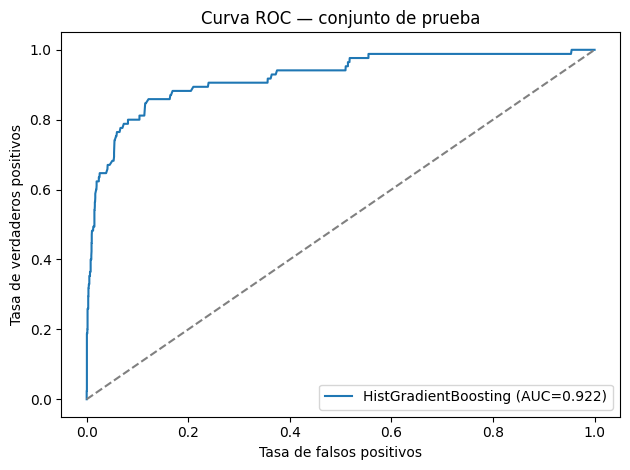

In [10]:
def calcular_metricas(y_true, y_pred, y_proba=None):
    d = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_proba is not None:
        d["roc_auc"] = roc_auc_score(y_true, y_proba)
    return d

# Predicciones train y test del modelo final
y_train_pred = best_model.predict(X_train)
y_train_proba = best_model.predict_proba(X_train)[:, 1]

y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

# Baseline en test
y_base_pred = baseline.predict(X_test)
y_base_proba = baseline.predict_proba(X_test)[:, 1]

filas_test = []
for nombre, pred, proba in [
    ("Línea base (clase mayoritaria)", y_base_pred, y_base_proba),
    (best_name, y_test_pred, y_test_proba)
]:
    fila = {"modelo": nombre}
    fila.update(calcular_metricas(y_test, pred, proba))
    filas_test.append(fila)

test_resumen = pd.DataFrame(filas_test)
test_resumen.to_csv("output/metricas_test.csv", index=False)
print("\nMétricas test:")
display(test_resumen.round(4))

# Brecha sobreajuste
gap = pd.DataFrame([{
    "modelo": best_name,
    "accuracy_train": accuracy_score(y_train, y_train_pred),
    "accuracy_test": accuracy_score(y_test, y_test_pred),
    "f1_train": f1_score(y_train, y_train_pred, zero_division=0),
    "f1_test": f1_score(y_test, y_test_pred, zero_division=0),
    "roc_auc_train": roc_auc_score(y_train, y_train_proba),
    "roc_auc_test": roc_auc_score(y_test, y_test_proba),
}])
gap["brecha_f1"] = gap["f1_train"] - gap["f1_test"]
gap["brecha_auc"] = gap["roc_auc_train"] - gap["roc_auc_test"]
gap.to_csv("output/brecha_sobreajuste.csv", index=False)
print("\nBrecha train-test:")
display(gap.round(4))

# Matriz de confusión
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Asiste (0)", "No asiste (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matriz de confusión — {best_name}")
plt.tight_layout()
plt.savefig("output/matriz_confusion.png", dpi=200)
plt.show()
plt.close()

# Reporte por clase
reporte = classification_report(
    y_test, y_test_pred,
    target_names=["Asiste (0)", "No asiste (1)"],
    zero_division=0
)
with open("output/classification_report.txt", "w", encoding="utf-8") as f:
    f.write(reporte)
print("\nReporte de clasificación:")
display(reporte)

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
plt.figure()
plt.plot(fpr, tpr, label=f"{best_name} (AUC={roc_auc_score(y_test, y_test_proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — conjunto de prueba")
plt.legend()
plt.tight_layout()
plt.savefig("output/curva_roc.png", dpi=200)
plt.show()
plt.close()

### 8. Interpretación: importancia de variables


Importancia por permutación:


,variable,importancia_media,importancia_std
0,P02,0.440204,0.037094
1,añoest,0.092791,0.009929
3,nivel_educ_simplificado,0.012477,0.004100
2,NOMBRE_DPTO,0.005724,0.004635


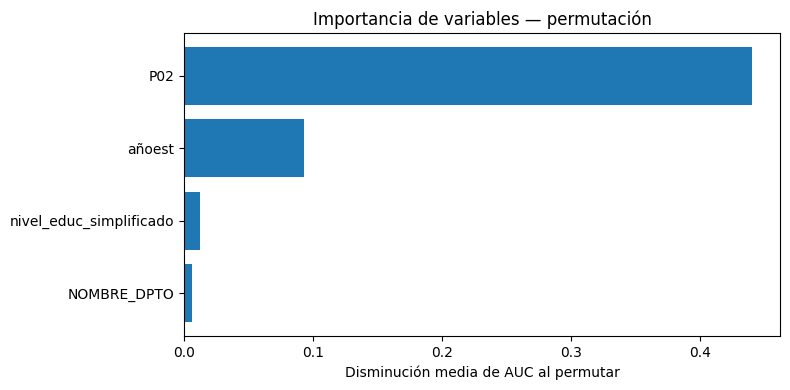


Coeficientes logísticos:


,feature,coeficiente,odds_ratio
0,num__P02,4.304195,74.009617
22,cat__nivel_educ_simplificado_Sin instrucción,1.562995,4.773095
18,cat__nivel_educ_simplificado_Alfabetización/es...,0.730083,2.075254
15,cat__NOMBRE_DPTO_Presidente Hayes,0.709058,2.032076
16,cat__NOMBRE_DPTO_San Pedro,0.581185,1.788157
3,cat__NOMBRE_DPTO_Amambay,0.405552,1.500130
9,cat__NOMBRE_DPTO_Concepción,0.151082,1.163092
2,cat__NOMBRE_DPTO_Alto Paraná,0.111971,1.118480
5,cat__NOMBRE_DPTO_Caaguazú,0.015335,1.015454
7,cat__NOMBRE_DPTO_Canindeyú,0.003996,1.004004


In [11]:
# Importancia por permutación sobre test
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "variable": X_test.columns,
    "importancia_media": perm.importances_mean,
    "importancia_std": perm.importances_std
}).sort_values("importancia_media", ascending=False)

perm_df.to_csv("output/importancia_permutacion.csv", index=False)
print("\nImportancia por permutación:")
display(perm_df)

plt.figure(figsize=(8, 4))
plt.barh(perm_df["variable"], perm_df["importancia_media"])
plt.xlabel("Disminución media de AUC al permutar")
plt.title("Importancia de variables — permutación")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("output/importancia_permutacion.png", dpi=200)
plt.show()
plt.close()

# Coeficientes de la regresión logística
logit_model = search_logit.best_estimator_
prep = logit_model.named_steps["prep"]
clf = logit_model.named_steps["clf"]

nombres_features = prep.get_feature_names_out()
coefs = pd.DataFrame({
    "feature": nombres_features,
    "coeficiente": clf.coef_[0]
})
coefs["odds_ratio"] = np.exp(coefs["coeficiente"])
coefs = coefs.sort_values("coeficiente", ascending=False)
coefs.to_csv("output/coeficientes_logisticos.csv", index=False)
print("\nCoeficientes logísticos:")
display(coefs.head(20))

###9. Análisis de errores

In [12]:
test_df = X_test.copy()
test_df["y_true"] = y_test.values
test_df["y_pred"] = y_test_pred
test_df["prob_no_asiste"] = y_test_proba
test_df["error"] = (test_df["y_true"] != test_df["y_pred"]).astype(int)
test_df["tipo_error"] = np.select(
    [
        (test_df["y_true" ] == 1) & (test_df["y_pred"] == 0),
        (test_df["y_true"] == 0) & (test_df["y_pred"] == 1)
    ],
    ["Falso negativo: no asiste predicho como asiste",
     "Falso positivo: asiste predicho como no asiste"],
    default="Correcto"
)

test_df.to_csv("output/predicciones_test.csv", index=False)

err_dept = (
    test_df.groupby("NOMBRE_DPTO")
    .apply(lambda d: pd.Series({
        "n": len(d),
        "errores": int(d["error"].sum()),
        "tasa_error": d["error"].mean(),
        "falsos_negativos": int(((d["y_true"] == 1) & (d["y_pred"] == 0)).sum()),
        "falsos_positivos": int(((d["y_true"] == 0) & (d["y_pred"] == 1)).sum()),
    }))
    .sort_values("tasa_error", ascending=False)
)
err_dept.to_csv("output/errores_por_departamento.csv")
print("\nErrores por departamento:")
display(err_dept.round(4))

peores = test_df.sort_values("prob_no_asiste", ascending=False).head(30)
peores.to_csv("output/casos_peor_predichos.csv", index=False)
print("\nCasos peores predichos:")
display(peores)


Errores por departamento:


,n,errores,tasa_error,falsos_negativos,falsos_positivos
NOMBRE_DPTO,,,,,
Canindeyú,177.0,12.0,0.0678,8.0,4.0
Amambay,62.0,4.0,0.0645,2.0,2.0
Itapúa,191.0,10.0,0.0524,9.0,1.0
Guairá,119.0,5.0,0.0420,4.0,1.0
Alto Paraná,246.0,10.0,0.0407,7.0,3.0
Paraguarí,50.0,2.0,0.0400,2.0,0.0
Misiones,122.0,3.0,0.0246,3.0,0.0
Caaguazú,168.0,4.0,0.0238,3.0,1.0
San Pedro,201.0,4.0,0.0199,1.0,3.0



Casos peores predichos:


,P02,añoest,NOMBRE_DPTO,nivel_educ_simplificado,y_true,y_pred,prob_no_asiste,error,tipo_error
12691,17,3,Guairá,Primaria (EEB 1-6),1,1,0.937487,0,Correcto
16550,17,6,Caaguazú,Primaria (EEB 1-6),1,1,0.936400,0,Correcto
12581,17,6,Guairá,Primaria (EEB 1-6),0,1,0.918323,1,Falso positivo: asiste predicho como no asiste
21093,17,6,Itapúa,Primaria (EEB 1-6),1,1,0.917087,0,Correcto
4996,17,6,Concepción,Primaria (EEB 1-6),1,1,0.917087,0,Correcto
27994,17,6,Paraguarí,Primaria (EEB 1-6),1,1,0.908797,0,Correcto
30424,17,6,Alto Paraná,Primaria (EEB 1-6),1,1,0.903251,0,Correcto
48398,17,7,Canindeyú,Secundaria/Media,1,1,0.894366,0,Correcto
48293,17,7,Canindeyú,Secundaria/Media,1,1,0.894366,0,Correcto
47852,17,12,Canindeyú,Secundaria/Media,1,1,0.854827,0,Correcto


###10. Serialización del modelo y parámetros

In [13]:
joblib.dump(best_model, "output/modelo_fase3.joblib")

with open("output/best_params.json", "w", encoding="utf-8") as f:
    json.dump({
        "modelo": best_name,
        "hiperparametros": busquedas[best_name].best_params_,
        "f1_cv": busquedas[best_name].best_score_,
        "variables_numericas": num_cols,
        "variables_categoricas": cat_cols,
        "target": "target_no_asiste = 1 si asiste_actualmente == 0"
    }, f, ensure_ascii=False, indent=2)

print("\nArchivos generados en /output:")
for f in sorted(os.listdir("output")):
    print(" -", f)


Archivos generados en /output:
 - best_params.json
 - brecha_sobreajuste.csv
 - casos_peor_predichos.csv
 - classification_report.txt
 - coeficientes_logisticos.csv
 - curva_roc.png
 - errores_por_departamento.csv
 - importancia_permutacion.csv
 - importancia_permutacion.png
 - matriz_confusion.png
 - metricas_cv.csv
 - metricas_test.csv
 - modelo_fase3.joblib
 - predicciones_test.csv


```markdown
### Guía: Uso del modelo guardado en otro cuaderno

El siguiente bloque de código muestra cómo cargar el pipeline entrenado y realizar predicciones sobre nuevos estudiantes sin necesidad de volver a definir el preprocesamiento manualmente.
```

In [ ]:
# ==========================================================
# COPIA ESTE CÓDIGO EN TU NUEVO CUADERNO DE COLAB
# (Asegúrate de subir el archivo 'modelo_fase3.joblib' primero y colocar su ruta)
# ==========================================================

import joblib
import pandas as pd

# 1. Cargar el pipeline completo
nombre_archivo = 'modelo_fase3.joblib'
modelo_cargado = joblib.load(nombre_archivo)
print("¡Modelo cargado correctamente desde", nombre_archivo, "!")

# 2. Definir nuevos datos de entrada (con las mismas columnas del entrenamiento)
nuevos_estudiantes = pd.DataFrame({
    "P02": [16, 7, 12],
    "añoest": [4, 0, 6],
    "NOMBRE_DPTO": ["Itapúa", "Asunción", "Canindeyú"],
    "nivel_educ_simplificado": ["Primaria (EEB 1-6)", "Inicial/especial", "Primaria (EEB 1-6)"]
})

# 3. Realizar predicciones directas
# El pipeline se encarga de imputar, escalar y aplicar One-Hot Encoding automáticamente
predicciones = modelo_cargado.predict(nuevos_estudiantes)
probabilidades = modelo_cargado.predict_proba(nuevos_estudiantes)[:, 1]

# 4. Mostrar los resultados consolidados
nuevos_estudiantes["Predicción"] = predicciones
nuevos_estudiantes["Probabilidad Deserción"] = probabilities_formatted = [f"{p:.2%}" for p in probabilidades]

display(nuevos_estudiantes)

FileNotFoundError: [Errno 2] No such file or directory: 'modelo_fase3.joblib'